In [150]:
%reload_ext autoreload
%autoreload 2

from datetime import datetime, timezone
import pytz
from time import sleep
import numpy as np
from websocket import create_connection
import json
import threading
import traceback
from scipy.optimize import linprog
import matplotlib.pyplot as plt
import csv

from compute_ror_prob import compute_floor_price, compute_ror_with_gbm
from functions import calculate_l_v
from trading_api_functions import get_recent_btc_data, get_kalshi_btc_spreads

In [185]:
bankroll = 10
risk_threshold = 0.5
W_star = np.array([[13.679065723383944, 0.0015147325961468935], [13.368204603123749, 0.048394936350589265], [16.917230858029583, 0.0029225052506628227], [0.9982390884308507, -0.12255025377961974], [0.29993190495735017, 0.6265727935554379], [0.7939537449682297, -0.07330843578986802]])
deg = 2
lookahead_time = 2 * 3600 * 10 # Keep to 2 hours because prediction falls off after that

In [184]:
deltas = [5, 25, 50, 100, 120] # in minutes
ps = [-0.005, -0.01, -0.015, -0.02, -0.025]
for d in deltas:
    for p in ps:
        l, v = calculate_l_v(W_star, deg, d, p)
        print(f"Delta: {d}, P: {p}, Window Size: {l}, Nu: {v}")


Delta: 5, P: -0.005, Window Size: 14, Nu: 0.6948795501345653
Delta: 5, P: -0.01, Window Size: 14, Nu: 0.6949494986267793
Delta: 5, P: -0.015, Window Size: 14, Nu: 0.6950176158571985
Delta: 5, P: -0.02, Window Size: 14, Nu: 0.6950839014519905
Delta: 5, P: -0.025, Window Size: 14, Nu: 0.6951483550474009
Delta: 25, P: -0.005, Window Size: 16, Nu: 0.6966249316738794
Delta: 25, P: -0.01, Window Size: 16, Nu: 0.6969570323924218
Delta: 25, P: -0.015, Window Size: 16, Nu: 0.6972874023176142
Delta: 25, P: -0.02, Window Size: 16, Nu: 0.6976160396399617
Delta: 25, P: -0.025, Window Size: 16, Nu: 0.6979429425600333
Delta: 50, P: -0.005, Window Size: 19, Nu: 0.6940082226804221
Delta: 50, P: -0.01, Window Size: 19, Nu: 0.6946662415159365
Delta: 50, P: -0.015, Window Size: 19, Nu: 0.6953228556155256
Delta: 50, P: -0.02, Window Size: 19, Nu: 0.6959780613746627
Delta: 50, P: -0.025, Window Size: 19, Nu: 0.6966318551985512
Delta: 100, P: -0.005, Window Size: 25, Nu: 0.6730350886017107
Delta: 100, P: -0.

In [40]:
stop_coinbase_webstream = False

In [41]:
btc_df = get_recent_btc_data()
btc_df.loc[len(btc_df) - 1, 'Date'] = btc_df.loc[len(btc_df) - 1, 'Date'].to_pydatetime()

def coinbase_btc_listener():
    coinbase_ws = create_connection('wss://ws-feed.exchange.coinbase.com')
    subscription_msg = {
        "type": "subscribe",
        "channels": [
            {"name": "ticker", "product_ids": ["BTC-USD"]}
        ]
    }
    coinbase_ws.send(json.dumps(subscription_msg))
    while True:
        try:
            if coinbase_ws is None or not coinbase_ws.connected:
                coinbase_ws = create_connection('wss://ws-feed.exchange.coinbase.com')
                coinbase_ws.send(json.dumps(subscription_msg))
                print("Resubscribed to coinbase ws")
            if stop_coinbase_webstream:
                unsubscription_msg = {
                    "type": "unsubscribe",
                    "channels": [
                        {"name": "ticker", "product_ids": ["BTC-USD"]}
                    ]
                }
                coinbase_ws.send(json.dumps(unsubscription_msg))
                print("successfully unsubscribed")
                break
            msg = json.loads(coinbase_ws.recv())
            if msg.get("type") == "ticker":
                btc_price_time = datetime.now(pytz.timezone("America/Chicago"))
                btc_price = float(msg["price"])
                if btc_price_time.minute != btc_df.loc[len(btc_df) - 1, 'Date'].minute:
                    btc_df.loc[len(btc_df) - 1, 'Price'] = (btc_df.loc[len(btc_df) - 1, 'Low'] + btc_df.loc[len(btc_df) - 1, 'High']) / 2.0
                    btc_df.loc[len(btc_df)] = ['', btc_price_time, btc_price, btc_price, btc_price]
                else:
                    low_price = min(btc_df.loc[len(btc_df) - 1, 'Low'], btc_price)
                    high_price = max(btc_df.loc[len(btc_df) - 1, 'High'], btc_price)
                    btc_df.loc[len(btc_df) - 1] = ['', btc_price_time, low_price, high_price, btc_price]
        except Exception:
            traceback.print_exc()
            sleep(1) 

threading.Thread(target=coinbase_btc_listener, daemon=True).start()


In [177]:
def compute_payout(alpha_opt, r_no, r_yes, p_f_arr, ror_price, p_0, investment, num_points=100):
    p_end = 2 * p_0 - ror_price
    p_vals = np.linspace(ror_price, p_end, num_points)
    g_vals = []
    kalshi_a_no = alpha_opt[1: len(r_no) + 1]
    kalshi_a_yes = alpha_opt[len(r_no) + 1:]
    for p in p_vals:
        no_hit = np.sum(kalshi_a_no[p_f_arr > p] * (r_no[p_f_arr > p] - 1))
        no_miss = np.sum(kalshi_a_no[p_f_arr <= p])
        yes_hit = np.sum(kalshi_a_yes[p_f_arr <= p] * (r_yes[p_f_arr <= p] - 1))
        yes_miss = np.sum(kalshi_a_yes[p_f_arr > p])
        g_vals.append((alpha_opt[0] * (p - p_0) / p_0 + no_hit - no_miss + yes_hit - yes_miss) * investment)
    return p_vals, np.array(g_vals)

def plot_payout(alpha_opt, r_no, r_yes, p_f_arr, p_0, ror_price, investment, num_points=100):
    p_vals, g_vals = compute_payout(alpha_opt, r_no, r_yes, p_f_arr, ror_price, p_0, investment, num_points)
    print(p_vals)
    print(g_vals)
    plt.figure()
    plt.plot(p_vals, g_vals)
    plt.xlabel('Price (p)')
    plt.ylabel('Payout g(p)')
    plt.title('Payout vs Price')
    plt.show()

In [ ]:
a = [0.49974529, 0.50025471, 0]
r_no = [1.03092784]
r_yes = [12.5]
p_f_arr = [108000]


Delta (min): 846.5300166166667
Current BTC Price: 107936.66
Window Size- 157, Nu- 0.003261090916157843, ROR Price- 108710.65844557513
Kalshi Buckets Length: 6
c_obj: [ 0.         -0.13406703 -0.08022428 -0.04517026 -0.0242378  -0.01980119
 -0.03153442  1.30413619  2.03382138  3.12372772  4.11554581  5.84906677
  0.91878202], A_eq: [[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]], b_eq: [1], A_ub: (7, 13), b_ub: [0, 0, 0, 0, 0, 0, 0], bounds: [(-1, 1), (0, 2), (0, 2), (0, 2), (0, 2), (0, 2), (0, 2), (0, 2), (0, 2), (0, 2), (0, 2), (0, 2), (0, 2)]
p_f_arr: [109000 109500 110000 110500 111000 112000]
r_no: [1.25       1.13636364 1.06382979 1.02040816 1.01010101 1.03092784]
r_yes: [ 3.57142857  5.          7.14285714  9.09090909 12.5         2.77777778]
True
        message: Optimization terminated successfully. (HiGHS Status 7: Optimal)
        success: True
         status: 0
            fun: -0.002503342614633829
              x: [ 9.637e-01  1.083e-02 ...  0.000e+00  0.000e+00]
            ni

<string>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


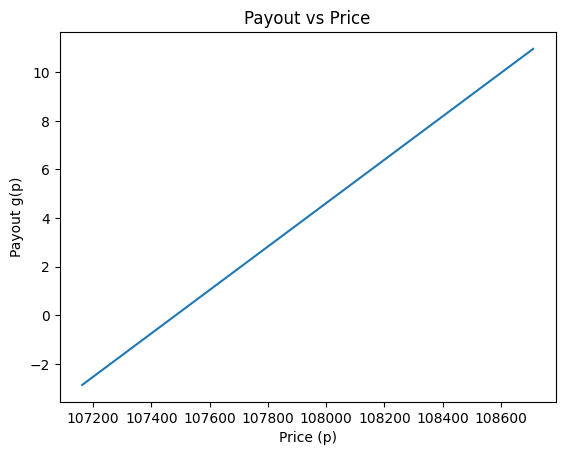

In [ ]:
window_size = None
nu = None
ror_price = None
opps_found = 0
while True:
    kalshi_df = get_kalshi_btc_spreads(lookahead_time)
    close_time = kalshi_df.loc[0, 'close_time']
    kalshi_df = kalshi_df[kalshi_df['close_time'] == close_time]

    dt_now = datetime.now(pytz.timezone("America/Chicago"))
    delta_min = (close_time - dt_now).total_seconds() / 60.0
    print(f"Delta (min): {delta_min}")

    p_0 = btc_df.loc[len(btc_df) - 1, 'Price']
    ror_price = p_0
    print(f"Current BTC Price: {p_0}")

    # Simple loop to determine gbm params and ror_price
    while True:
        new_window_size, new_nu = calculate_l_v(W_star, deg, delta_min, (ror_price - p_0) / p_0)

        btc_win = btc_df.tail(new_window_size)
        new_ror_price = compute_floor_price(delta_min, btc_win, p_0, new_nu, risk_threshold)
        if window_size == new_window_size and round(nu, 5) == round(new_nu, 5) and round(ror_price, 5) == round(new_ror_price, 5):
            window_size = new_window_size
            nu = new_nu
            ror_price = new_ror_price
            print(f"Window Size- {window_size}, Nu- {nu}, ROR Price- {ror_price}")
            break
        else:
            window_size = new_window_size
            nu = new_nu
            ror_price = new_ror_price
            
    kalshi_buckets = kalshi_df[kalshi_df['ceil_price'] > ror_price]
    kalshi_buckets = kalshi_buckets[kalshi_buckets['no_ask'] != 100]
    kalshi_buckets = kalshi_buckets[::-1].reset_index(drop=True)
    print(f"Kalshi Buckets Length: {len(kalshi_buckets)}")

    r_no = 100 / np.array(kalshi_buckets['no_ask'].to_list()) # ratio payout from bucket 
    r_yes = 100 / np.array(kalshi_buckets['yes_ask'].to_list())
    p_f_arr = np.array(kalshi_buckets['ceil_price'].to_list())
    btc_win = btc_df.tail(window_size)
    F = compute_ror_with_gbm(p_f_arr, delta_min, btc_win, p_0=p_0, nu_arr=nu) # CDF for bucket price
    # C = np.array([1] * (len(r_no) + 1)) # Set by subbing to kalshi websocket
    n = len(r_no)

    # Objective: maximize c^T alpha => minimize -c^T alpha (assuming E(p) = 0 so then a_0 not in obj function)
    c = np.concatenate(((r_no + 1) * F - 1, -(r_yes + 1) * F + 1))
    c_obj = np.concatenate((np.array([0]), -c))

    # Bounds for alpha_i: 0 <= alpha_i <= C_i
    bounds = [(-1, 1)] + [(0, 2) for _ in range(2 * n)]

    A_eq = [[1] * (2 * n + 1)]
    b_eq = [1]

    # Inequality constraints: g(i^+) >= 0 => -g(i^+) <= 0
    A_ub = []
    b_ub = []

    # Positive until lower risk threshold
    A_ub.append([-(ror_price - p_0) / p_0] + [-(i - 1) for i in r_no] + [1] * n)
    b_ub.append(0)

    # Conditions for buckets no side
    for i in range(n):
        row = np.zeros(2 * n + 1, dtype=float)
        row[0] = -(p_f_arr[i] - p_0) / p_0
        for j in range(i + 1, n):
            row[j + 1] = -(r_no[j] - 1)
            row[j + 1 + n] = 1
        for j in range(i + 1):
            row[j + 1] = 1
            row[j + 1 + n] = -(r_yes[j] - 1)

        A_ub.append(row.tolist())
        b_ub.append(0)

    for i in range(n):
        row = np.zeros(2 * n + 1, dtype=float)
        row[0] = -(p_f_arr[i] - p_0) / p_0
        for j in range(i, n):
            row[j + 1] = -(r_no[j] - 1)
            row[j + 1 + n] = 1
        for j in range(i):
            row[j + 1] = 1
            row[j + 1 + n] = -(r_yes[j] - 1)

        A_ub.append(row.tolist())
        b_ub.append(0)

    print(f"c_obj: {c_obj}, A_eq: {A_eq}, b_eq: {b_eq}, A_ub: {np.array(A_ub).shape}, b_ub: {b_ub}, bounds: {bounds}")

    A_ub = np.array(A_ub)
    # Solve LP
    result = linprog(c=c_obj, A_eq=A_eq, b_eq=b_eq, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method='highs')

    print(f"p_f_arr: {p_f_arr}")
    print(f"r_no: {r_no}")
    print(f"r_yes: {r_yes}")
    print(result.success)
    print(result)
    if result.success:
        opps_found += 1
        print(f"a: {result.x}")
        a = result.x

        with open('results/invest_opps.csv', 'a', newline='') as f:
            writer = csv.writer(f)
            writer.writerow([
                datetime.now().isoformat(),
                a,
                r_no,
                r_yes,
                p_f_arr,
                ror_price,
                p_0
            ])
        
        plot_payout(a, r_no, r_yes, p_f_arr, p_0, ror_price, investment=1000)
        break
    
    print(f"Opportunities found: {opps_found}")


    sleep(3)
